# PjBL — RA1: Ingestão e Preparação dos Dados

## Preços de combustíveis no Brasil (ANP)

**Equipe:** Eduardo Pereira, Patrick de Oliveira, Roberto Zhou, Matheus Fraiz de Camargo Antonello

Este notebook desenvolve a primeira etapa do projeto: obter os dados, carregá-los, entender o que eles representam, avaliar a qualidade e preparar uma base confiável para as próximas etapas.

> **Pergunta central do projeto:** quais fatores estão associados à variação do preço dos combustíveis entre os postos brasileiros?

### Fluxo

**Carregar → Conhecer → Inspecionar → Identificar problemas → Decidir → Transformar → Validar**

Seguimos a ideia **Inspect → Decide → Transform → Validate**: primeiro olhamos os dados, depois decidimos o que fazer, só então transformamos, e no final conferimos se o resultado ficou como planejado.

## Preparação do ambiente

Importamos as bibliotecas e definimos um padrão visual para tabelas e gráficos. O notebook roda tanto localmente quanto no Google Colab.

In [1]:
# Bibliotecas para download, manipulação e visualização dos dados
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configurações que deixam os resultados mais legíveis
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

print("✓ Ambiente preparado.")

✓ Ambiente preparado.


# 1. Carregar

A primeira etapa é a **ingestão**: trazer os dados da fonte para o ambiente do projeto.

Os dados vêm do **Levantamento de Preços de Combustíveis** da ANP (Agência Nacional do Petróleo, Gás Natural e Biocombustíveis), disponível em:
https://www.gov.br/anp/pt-br/centrais-de-conteudo/dados-abertos/serie-historica-de-precos-de-combustiveis

A ANP publica **um arquivo CSV por mês** para cada grupo de produtos:

| Grupo | Produtos |
|---|---|
| `gasolina-etanol` | Gasolina, Gasolina Aditivada, Etanol |
| `diesel-gnv` | Diesel, Diesel S10, GNV |
| `glp` | GLP (botijão de 13 kg) |

Usamos o período de **janeiro/2023 a agosto/2026**.

## 1.1 Montar a lista de arquivos

De 2023 a 2025 o nome dos arquivos segue sempre o mesmo padrão, então a lista pode ser gerada com um laço. Em 2026 isso não funciona: a ANP mudou o padrão de nome mais de uma vez e publicou o arquivo de fevereiro com erro de digitação (`cados-abertos-preco` em vez de `dados-abertos-precos`). Por isso os nomes de 2026 foram copiados da página da ANP.

Abril de 2026 **não foi publicado** pela ANP para nenhum grupo. Conferimos a página em 23/09/2026 e de novo em 14/10/2026.

In [2]:
# Endereço base dos arquivos mensais
URL_BASE = "https://www.gov.br/anp/pt-br/centrais-de-conteudo/dados-abertos/arquivos/shpc/dsan"
GRUPOS = ["gasolina-etanol", "diesel-gnv", "glp"]

arquivos = []

# 2023 a 2025: o nome do arquivo segue sempre o mesmo padrão
for ano in [2023, 2024, 2025]:
    for mes in range(1, 13):
        for grupo in GRUPOS:
            arquivos.append({
                "ano": ano, "mes": mes, "grupo": grupo,
                "url": f"{URL_BASE}/{ano}/precos-{grupo}-{mes:02d}.csv",
            })

# 2026: nomes copiados da página da ANP (o padrão muda de um mês para outro)
NOMES_2026 = {
    (1, "gasolina-etanol"): "01-dados-abertos-precos-gasolina-etanol.csv",
    (1, "diesel-gnv"):      "01-dados-abertos-precos-diesel-gnv.csv",
    (1, "glp"):             "01-dados-abertos-precos-glp.csv",
    (2, "gasolina-etanol"): "02-cados-abertos-preco-gasolina-etanol.csv",  # erro de digitação da ANP
    (2, "diesel-gnv"):      "02-dados-abertos-precos-diesel-gnv.csv",
    (2, "glp"):             "02-dados-abertos-precos-glp.csv",
    (3, "gasolina-etanol"): "03-dados-abertos-precos-gasolina-etanol.csv",
    (3, "diesel-gnv"):      "03-dados-abertos-precos-diesel-gnv.csv",
    (3, "glp"):             "03-dados-abertos-precos-glp.csv",
    # abril/2026 não foi publicado
    (5, "gasolina-etanol"): "05-dados-abertos-precos-gasolina-etanol.csv",
    (5, "diesel-gnv"):      "05-dados-abertos-precos-diesel-gnv.csv",
    (5, "glp"):             "05-dados-abertos-precos-glp.csv",
    (6, "gasolina-etanol"): "06-dados-abertos-precos-2026-06-gasolina-etanol.csv",
    (6, "diesel-gnv"):      "06-dados-abertos-precos-2026-06-diesel-gnv.csv",
    (6, "glp"):             "06-dados-abertos-precos-2026-06-glp.csv",
    (7, "gasolina-etanol"): "07-dados-abertos-precos-gasolina-etanol.csv",
    (7, "diesel-gnv"):      "07-dados-abertos-precos-diesel-gnv.csv",
    (7, "glp"):             "07-dados-abertos-precos-glp.csv",
    (8, "gasolina-etanol"): "08-dados-abertos-precos-2026-08-gasolina-etanol.csv",
    (8, "diesel-gnv"):      "08-dados-abertos-precos-2026-08-diesel-gnv.csv",
    (8, "glp"):             "08-dados-abertos-precos-2026-08-glp.csv",
}
for (mes, grupo), nome in NOMES_2026.items():
    arquivos.append({"ano": 2026, "mes": mes, "grupo": grupo, "url": f"{URL_BASE}/2026/{nome}"})

MESES_AUSENTES = [(2026, 4)]

print(f"Arquivos na lista:        {len(arquivos)}")
print(f"Meses com dados:          {len(arquivos) // len(GRUPOS)}")
print(f"Meses ausentes na origem: {MESES_AUSENTES}")

Arquivos na lista:        129
Meses com dados:          43
Meses ausentes na origem: [(2026, 4)]


## 1.2 Baixar os arquivos

Os arquivos são salvos em `data/raw/` com um nome padronizado (`grupo_ano-mes.csv`), independentemente do nome usado pela ANP.

Dois cuidados:

- o site da ANP **recusa downloads automáticos** (erro 403) quando a requisição não informa de qual navegador e de qual página ela vem, então enviamos esses cabeçalhos;
- se um arquivo já foi baixado antes, ele **não é baixado de novo**. Assim o notebook pode ser executado várias vezes sem repetir o download.

Os arquivos de `data/raw/` não são alterados em nenhuma etapa e não vão para o repositório: quem executar este notebook baixa exatamente os mesmos arquivos da fonte oficial.

In [3]:
PASTA_RAW = os.path.join("data", "raw")
os.makedirs(PASTA_RAW, exist_ok=True)

# Sem esses cabeçalhos o site da ANP responde com erro 403
CABECALHOS = {
    "User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                   "(KHTML, like Gecko) Chrome/140.0 Safari/537.36"),
    "Referer": ("https://www.gov.br/anp/pt-br/centrais-de-conteudo/dados-abertos/"
                "serie-historica-de-precos-de-combustiveis"),
}

for item in arquivos:
    item["arquivo"] = f"{item['grupo']}_{item['ano']}-{item['mes']:02d}.csv"
    caminho = os.path.join(PASTA_RAW, item["arquivo"])

    # Arquivo já baixado em uma execução anterior
    if os.path.exists(caminho):
        item["status"] = "já existia"
        continue

    resposta = requests.get(item["url"], headers=CABECALHOS, timeout=180)
    if resposta.status_code == 200:
        with open(caminho, "wb") as f:
            f.write(resposta.content)
        item["status"] = "baixado"
    else:
        item["status"] = f"erro {resposta.status_code}"

controle = pd.DataFrame(arquivos)

print("RESULTADO DO DOWNLOAD")
print("─" * 50)
display(controle["status"].value_counts().to_frame("arquivos"))

erros = controle[controle["status"].str.startswith("erro")]
assert erros.empty, f"Falha ao baixar {len(erros)} arquivo(s):\n{erros[['arquivo', 'status']]}"

tamanho_mb = sum(os.path.getsize(os.path.join(PASTA_RAW, a)) for a in controle["arquivo"]) / 1e6
print(f"✓ {len(controle)} arquivos disponíveis em data/raw/ ({tamanho_mb:,.0f} MB)")

RESULTADO DO DOWNLOAD
──────────────────────────────────────────────────


,arquivos
status,
já existia,129


✓ 129 arquivos disponíveis em data/raw/ (633 MB)


## 1.3 Ler e juntar os arquivos

Todos os arquivos são lidos e empilhados em um único DataFrame, `df_original`. Ele preserva o conteúdo recebido e **não será alterado** nas etapas seguintes.

Decisões de leitura:

- `sep=";"`: os arquivos usam ponto e vírgula como separador;
- `encoding="utf-8-sig"`: os arquivos começam com um BOM (marca invisível de codificação). O pandas já ignora essa marca sozinho, mas deixamos o encoding explícito porque outras ferramentas, como o Spark, podem não ignorar;
- `dtype="string[pyarrow]"`: tudo é lido como **texto**. Converter tipos é uma decisão de limpeza e fica para a etapa 6. Usamos o tipo de texto do pyarrow em vez do padrão porque ele ocupa cerca de **três vezes menos memória**: medimos 1,2 GB contra 3,7 GB para esta base. Com 3,7 milhões de linhas e algumas cópias da tabela ao longo do notebook, isso é o que permite executá-lo no Google Colab sem estourar a memória;
- `keep_default_na=False` e `na_values=[""]`: por padrão o pandas transforma textos como `"NA"` e `"NULL"` em ausentes. Aqui só consideramos ausente a célula realmente vazia, para não esconder o que veio no arquivo.

Também conferimos se todos os arquivos têm o mesmo cabeçalho, já que eles foram publicados ao longo de quase quatro anos.

In [4]:
# Cabeçalho esperado em todos os arquivos da ANP
COLUNAS_ESPERADAS = [
    "Regiao - Sigla", "Estado - Sigla", "Municipio", "Revenda", "CNPJ da Revenda",
    "Nome da Rua", "Numero Rua", "Complemento", "Bairro", "Cep", "Produto",
    "Data da Coleta", "Valor de Venda", "Valor de Compra", "Unidade de Medida", "Bandeira",
]

partes = []
for item in arquivos:
    df = pd.read_csv(
        os.path.join(PASTA_RAW, item["arquivo"]),
        sep=";",
        encoding="utf-8-sig",
        dtype="string[pyarrow]",
        keep_default_na=False,
        na_values=[""],
    )
    item["linhas"] = len(df)
    item["mesmo_cabecalho"] = list(df.columns) == COLUNAS_ESPERADAS
    df["arquivo_origem"] = item["arquivo"]
    partes.append(df)

df_original = pd.concat(partes, ignore_index=True)
controle = pd.DataFrame(arquivos)

print("✓ Dados carregados com sucesso!")
print(f"Arquivos lidos:                       {len(partes)}")
print(f"Arquivos com cabeçalho diferente:     {(~controle['mesmo_cabecalho']).sum()}")
print(f"Shape: {df_original.shape[0]:,} linhas × {df_original.shape[1]} colunas")
print("\nPrimeiras linhas da base recebida:")
display(df_original.head())

✓ Dados carregados com sucesso!
Arquivos lidos:                       129
Arquivos com cabeçalho diferente:     0
Shape: 3,717,753 linhas × 17 colunas

Primeiras linhas da base recebida:


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira,arquivo_origem
0,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL 220 - KM 06,S/N,<NA>,PLANALTO,57308-000,ETANOL,02/01/2023,"3,89",<NA>,R$ / litro,VIBRA ENERGIA,gasolina-etanol_2023-01.csv
1,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL 220 - KM 06,S/N,<NA>,PLANALTO,57308-000,GASOLINA ADITIVADA,02/01/2023,"5,14",<NA>,R$ / litro,VIBRA ENERGIA,gasolina-etanol_2023-01.csv
2,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL 220 - KM 06,S/N,<NA>,PLANALTO,57308-000,GASOLINA,02/01/2023,"5,14",<NA>,R$ / litro,VIBRA ENERGIA,gasolina-etanol_2023-01.csv
3,NE,AL,ARAPIRACA,AUTO POSTO SAO FRANCISCO LTDA,12.706.529/0001-04,RUA SAO FRANCISCO,274,<NA>,CENTRO,57300-080,ETANOL,02/01/2023,"3,79",<NA>,R$ / litro,VIBRA ENERGIA,gasolina-etanol_2023-01.csv
4,NE,AL,ARAPIRACA,AUTO POSTO SAO FRANCISCO LTDA,12.706.529/0001-04,RUA SAO FRANCISCO,274,<NA>,CENTRO,57300-080,GASOLINA,02/01/2023,"5,29",<NA>,R$ / litro,VIBRA ENERGIA,gasolina-etanol_2023-01.csv


In [5]:
# Quantos registros vieram de cada grupo em cada ano
registros_por_ano = controle.pivot_table(index="ano", columns="grupo", values="linhas", aggfunc="sum")
registros_por_ano["total"] = registros_por_ano.sum(axis=1)
registros_por_ano.loc["total"] = registros_por_ano.sum()

print("REGISTROS CARREGADOS POR ANO E GRUPO")
display(registros_por_ano.style.format("{:,.0f}"))

# Guardamos o controle da ingestão: qual arquivo veio de qual URL e com quantas linhas
controle[["ano", "mes", "grupo", "arquivo", "url", "linhas"]].to_csv(
    os.path.join("data", "controle_ingestao.csv"), index=False
)
print("✓ Controle da ingestão salvo em data/controle_ingestao.csv")

REGISTROS CARREGADOS POR ANO E GRUPO


grupo,diesel-gnv,gasolina-etanol,glp,total
ano,,,,
2023,"294,565","610,912","228,302","1,133,779"
2024,"287,792","610,744","160,496","1,059,032"
2025,"248,742","555,836","125,203","929,781"
2026,"156,150","344,010","95,001","595,161"
total,"987,249","2,121,502","609,002","3,717,753"


✓ Controle da ingestão salvo em data/controle_ingestao.csv


# 2. Conhecer

Antes de procurar problemas, precisamos entender o que cada linha e cada coluna representam. Uma transformação tecnicamente correta pode ser analiticamente errada se ignorarmos o significado do dado.

**O que é uma linha:** o preço de **um produto**, em **um posto**, em **uma data**.

**Como o dado é produzido:** a ANP não registra o preço de todos os postos todos os dias. O levantamento é uma **pesquisa presencial por amostragem**: pesquisadores visitam postos selecionados e anotam o preço praticado na bomba. Por isso, qualquer conclusão futura vale para os postos pesquisados, e não para todo o mercado.

**Tipo de dado:** estruturado (tabela com colunas fixas, em CSV).

In [6]:
# Dicionário das colunas recebidas da ANP
dicionario = pd.DataFrame({
    "coluna": [
        "Regiao - Sigla", "Estado - Sigla", "Municipio", "Revenda", "CNPJ da Revenda",
        "Nome da Rua", "Numero Rua", "Complemento", "Bairro", "Cep",
        "Produto", "Data da Coleta", "Valor de Venda", "Valor de Compra",
        "Unidade de Medida", "Bandeira", "arquivo_origem",
    ],
    "significado": [
        "Região do país (N, NE, CO, SE, S)",
        "Unidade da federação",
        "Município do posto",
        "Nome (razão social) do posto",
        "CNPJ do posto",
        "Endereço do posto: rua",
        "Endereço do posto: número",
        "Endereço do posto: complemento",
        "Endereço do posto: bairro",
        "Endereço do posto: CEP",
        "Combustível pesquisado",
        "Data em que o preço foi coletado",
        "Preço cobrado do consumidor",
        "Preço pago pelo posto à distribuidora",
        "Unidade em que o preço está expresso",
        "Distribuidora à qual o posto é vinculado (BRANCA = sem vínculo)",
        "Criada por nós na ingestão: arquivo de onde a linha veio",
    ],
    "uso nas perguntas do projeto": [
        "sim — comparação entre regiões",
        "sim — o ICMS muda de estado para estado",
        "sim — concorrência entre postos da mesma cidade",
        "não",
        "sim — identifica o posto",
        "não", "não", "não", "não",
        "talvez — localização mais precisa no futuro",
        "sim — cada produto é analisado separadamente",
        "sim — evolução no tempo",
        "sim — é a variável principal",
        "seria útil (margem do posto), se tivesse dados",
        "sim — necessária para comparar preços",
        "sim — postos com e sem bandeira",
        "controle da ingestão",
    ],
})

display(dicionario.style.hide(axis="index"))

coluna,significado,uso nas perguntas do projeto
Regiao - Sigla,"Região do país (N, NE, CO, SE, S)",sim — comparação entre regiões
Estado - Sigla,Unidade da federação,sim — o ICMS muda de estado para estado
Municipio,Município do posto,sim — concorrência entre postos da mesma cidade
Revenda,Nome (razão social) do posto,não
CNPJ da Revenda,CNPJ do posto,sim — identifica o posto
Nome da Rua,Endereço do posto: rua,não
Numero Rua,Endereço do posto: número,não
Complemento,Endereço do posto: complemento,não
Bairro,Endereço do posto: bairro,não
Cep,Endereço do posto: CEP,talvez — localização mais precisa no futuro


In [7]:
# Quais produtos existem na base e em qual unidade cada um é vendido
produtos = (
    df_original.groupby(["Produto", "Unidade de Medida"])
    .size()
    .rename("registros")
    .reset_index()
    .sort_values("registros", ascending=False)
)

print("PRODUTOS PESQUISADOS")
display(produtos.style.format({"registros": "{:,}"}).hide(axis="index"))

PRODUTOS PESQUISADOS


Produto,Unidade de Medida,registros
GASOLINA,R$ / litro,"808,714"
ETANOL,R$ / litro,"684,106"
GASOLINA ADITIVADA,R$ / litro,"628,682"
GLP,R$ / 13 kg,"607,766"
DIESEL S10,R$ / litro,"570,952"
DIESEL,R$ / litro,"349,124"
GNV,R$ / m³,"65,696"


# 3. Inspecionar

A inspeção inicial responde perguntas básicas: qual é o tamanho da base, quais tipos o pandas atribuiria às colunas, onde há valores ausentes e se existem linhas repetidas.

Nesta etapa, **ainda não alteramos nada**.

In [8]:
print("VISÃO GERAL DA BASE ORIGINAL")
print("─" * 50)
print(f"Linhas:  {df_original.shape[0]:,}")
print(f"Colunas: {df_original.shape[1]}")
print(f"Células: {df_original.shape[0] * df_original.shape[1]:,}")

VISÃO GERAL DA BASE ORIGINAL
──────────────────────────────────────────────────
Linhas:  3,717,753
Colunas: 17
Células: 63,201,801


## 3.1 Tipos de dados

Lemos tudo como texto de propósito. Para ver o que aconteceria se o pandas escolhesse os tipos sozinho, lemos um dos arquivos sem nenhuma configuração além do separador.

In [9]:
amostra_padrao = pd.read_csv(os.path.join(PASTA_RAW, arquivos[0]["arquivo"]), sep=";")

tipos = pd.DataFrame({
    "tipo inferido pelo pandas": amostra_padrao.dtypes.astype(str),
    "exemplo de valor": amostra_padrao.iloc[0].astype(str),
})
tipos.index.name = "coluna"

print(f"Tipos inferidos ao ler {arquivos[0]['arquivo']} sem configurar nada:")
display(tipos)

Tipos inferidos ao ler gasolina-etanol_2023-01.csv sem configurar nada:


,tipo inferido pelo pandas,exemplo de valor
coluna,,
Regiao - Sigla,str,NE
Estado - Sigla,str,AL
Municipio,str,ARAPIRACA
Revenda,str,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...
CNPJ da Revenda,str,02.817.655/0001-82
Nome da Rua,str,RODOVIA AL 220 - KM 06
Numero Rua,str,S/N
Complemento,str,NaN
Bairro,str,PLANALTO


O preço (`Valor de Venda`) e a data (`Data da Coleta`) seriam lidos como **texto**: o preço usa vírgula como separador decimal e a data está no formato brasileiro `dd/mm/aaaa`. Já `Valor de Compra` vira número apenas porque a coluna está toda vazia.

## 3.2 Valores ausentes

VALORES AUSENTES NA BASE ORIGINAL


,quantidade ausente,percentual ausente (%)
Valor de Compra,"3,717,753",100.00%
Complemento,"2,850,289",76.67%
Bairro,"8,352",0.22%
Numero Rua,"3,236",0.09%
Regiao - Sigla,"2,713",0.07%
CNPJ da Revenda,"2,713",0.07%
Revenda,"2,713",0.07%
Municipio,"2,713",0.07%
Estado - Sigla,"2,713",0.07%
Nome da Rua,"2,713",0.07%


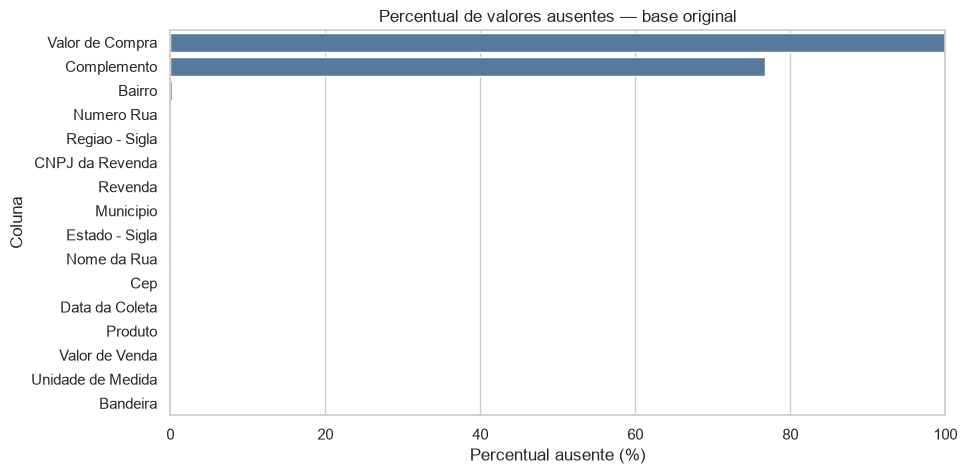

In [10]:
# Quantidade e percentual ajudam a avaliar a dimensão do problema
ausencias = pd.DataFrame({
    "quantidade ausente": df_original.isna().sum(),
    "percentual ausente (%)": df_original.isna().mean().mul(100),
}).sort_values("percentual ausente (%)", ascending=False)

print("VALORES AUSENTES NA BASE ORIGINAL")
display(ausencias.style.format({"quantidade ausente": "{:,}", "percentual ausente (%)": "{:.2f}%"}))

# Mostramos apenas as colunas que realmente possuem ausências
ausencias_grafico = ausencias[ausencias["quantidade ausente"] > 0]
plt.figure(figsize=(10, 5))
sns.barplot(
    data=ausencias_grafico.reset_index(),
    x="percentual ausente (%)", y="index", color="#4C78A8"
)
plt.title("Percentual de valores ausentes — base original")
plt.xlabel("Percentual ausente (%)")
plt.ylabel("Coluna")
plt.xlim(0, 100)
plt.show()

Três observações:

- `Valor de Compra` está **100% vazia**;
- `Complemento` está vazia em cerca de três quartos das linhas;
- quase todas as outras colunas têm **exatamente o mesmo número de ausentes** (2.713). Isso não parece coincidência: indica linhas inteiras vazias, o que investigamos na etapa 4.

## 3.3 Valores distintos e linhas repetidas

In [11]:
distintos = df_original.nunique().rename("valores distintos").to_frame()
distintos.index.name = "coluna"
print("QUANTIDADE DE VALORES DISTINTOS POR COLUNA")
display(distintos.style.format("{:,}"))

linhas_iguais = int(df_original.duplicated(subset=COLUNAS_ESPERADAS).sum())
print(f"\nLinhas repetidas (16 colunas iguais a outra linha): {linhas_iguais:,}")
print("⚠ Esse número ainda inclui as linhas vazias, que são todas iguais entre si.")

QUANTIDADE DE VALORES DISTINTOS POR COLUNA


,valores distintos
coluna,
Regiao - Sigla,5
Estado - Sigla,27
Municipio,471
Revenda,"20,592"
CNPJ da Revenda,"21,645"
Nome da Rua,"13,865"
Numero Rua,"5,033"
Complemento,"3,982"
Bairro,"7,987"



Linhas repetidas (16 colunas iguais a outra linha): 2,728
⚠ Esse número ainda inclui as linhas vazias, que são todas iguais entre si.


# 4. Identificar problemas

Agora investigamos cada suspeita levantada na inspeção e procuramos os problemas de qualidade vistos em aula: valores ausentes, registros duplicados, tipos incorretos, formatos inconsistentes, valores inválidos, categorias inconsistentes e possíveis outliers.

Para não alterar `df_original`, as verificações usam uma cópia (`df_inspecao`) e algumas colunas convertidas **temporariamente**, só para conseguir fazer as contas.

In [12]:
# Linhas em que as 16 colunas estão vazias
linha_vazia = df_original[COLUNAS_ESPERADAS].isna().all(axis=1)

# Cópia sem as linhas vazias; senão elas aparecem como problema em todas as verificações
df_inspecao = df_original[~linha_vazia].copy()

# Conversões temporárias, apenas para inspeção
preco = pd.to_numeric(df_inspecao["Valor de Venda"].str.replace(",", ".", regex=False), errors="coerce")
data = pd.to_datetime(df_inspecao["Data da Coleta"], format="%d/%m/%Y", errors="coerce")
cnpj = df_inspecao["CNPJ da Revenda"].str.replace(r"\D", "", regex=True)
mes_arquivo = df_inspecao["arquivo_origem"].str[-11:-4]   # "2025-06" a partir de "glp_2025-06.csv"
grupo = df_inspecao["arquivo_origem"].str.split("_").str[0]

print(f"Linhas totalmente vazias:      {linha_vazia.sum():,}")
print(f"Linhas usadas na inspeção:     {len(df_inspecao):,}")

Linhas totalmente vazias:      2,713
Linhas usadas na inspeção:     3,715,040


## 4.1 Linhas vazias

In [13]:
print("LINHAS VAZIAS POR ARQUIVO")
display(df_original.loc[linha_vazia, "arquivo_origem"].value_counts().to_frame("linhas vazias"))

# Como essas linhas aparecem no arquivo original
with open(os.path.join(PASTA_RAW, "diesel-gnv_2023-01.csv"), encoding="utf-8-sig") as f:
    linhas_arquivo = f.read().splitlines()

primeira_vazia = next(i for i, linha in enumerate(linhas_arquivo) if linha.strip(";") == "")
print(f"No arquivo diesel-gnv_2023-01.csv, as linhas vazias vão da linha {primeira_vazia + 1:,} até a última ({len(linhas_arquivo):,}).")
print(f"Conteúdo de uma delas: {linhas_arquivo[-1]!r}")

LINHAS VAZIAS POR ARQUIVO


,linhas vazias
arquivo_origem,
diesel-gnv_2023-01.csv,1477
glp_2023-01.csv,1236


No arquivo diesel-gnv_2023-01.csv, as linhas vazias vão da linha 21,963 até a última (23,439).
Conteúdo de uma delas: ';;;;;;;;;;;;;;;'


As 2.713 linhas vazias estão todas em **dois arquivos de janeiro/2023**, num bloco contínuo no fim do arquivo. Cada uma tem apenas os 15 separadores `;`, sem nenhum valor.

## 4.2 Registros duplicados e preços conflitantes

Além de linhas idênticas, verificamos a **chave natural** da base: um posto (CNPJ), um produto e uma data deveriam ter um único preço.

In [14]:
duplicada = df_inspecao.duplicated(subset=COLUNAS_ESPERADAS)

chave = pd.DataFrame({"cnpj": cnpj, "produto": df_inspecao["Produto"], "data": df_inspecao["Data da Coleta"]})
mesma_chave = chave.duplicated(keep=False)
identica = df_inspecao.duplicated(subset=COLUNAS_ESPERADAS, keep=False)
conflito = mesma_chave & ~identica

print("DUPLICATAS")
print("─" * 50)
print(f"Linhas idênticas a outra (excedentes):          {duplicada.sum():,}")
print(f"Arquivos onde aparecem:                         {sorted(df_inspecao.loc[duplicada, 'arquivo_origem'].unique())}")
print(f"Mesmo posto, produto e dia com preço diferente: {conflito.sum():,} linhas")

colunas_mostrar = ["Municipio", "Revenda", "CNPJ da Revenda", "Produto", "Data da Coleta", "Valor de Venda"]
display(df_inspecao.loc[conflito, colunas_mostrar].sort_values(["Produto", "Data da Coleta"]))

DUPLICATAS
──────────────────────────────────────────────────
Linhas idênticas a outra (excedentes):          16
Arquivos onde aparecem:                         ['diesel-gnv_2024-06.csv', 'diesel-gnv_2026-02.csv', 'gasolina-etanol_2024-06.csv', 'gasolina-etanol_2026-02.csv']
Mesmo posto, produto e dia com preço diferente: 8 linhas


,Municipio,Revenda,CNPJ da Revenda,Produto,Data da Coleta,Valor de Venda
1654536,TAUBATE,AUTO POSTO MANGUEIRA II LTDA,00.008.226/0001-39,GASOLINA,10/06/2024,"5,48"
1654538,TAUBATE,AUTO POSTO MANGUEIRA II LTDA,00.008.226/0001-39,GASOLINA,10/06/2024,"5,65"
1661787,TAUBATE,AUTO POSTO MANGUEIRA II LTDA,00.008.226/0001-39,GASOLINA,12/06/2024,"5,48"
1661789,TAUBATE,AUTO POSTO MANGUEIRA II LTDA,00.008.226/0001-39,GASOLINA,12/06/2024,"5,65"
1654537,TAUBATE,AUTO POSTO MANGUEIRA II LTDA,00.008.226/0001-39,GASOLINA ADITIVADA,10/06/2024,"5,59"
1654539,TAUBATE,AUTO POSTO MANGUEIRA II LTDA,00.008.226/0001-39,GASOLINA ADITIVADA,10/06/2024,"5,77"
1661788,TAUBATE,AUTO POSTO MANGUEIRA II LTDA,00.008.226/0001-39,GASOLINA ADITIVADA,12/06/2024,"5,59"
1661790,TAUBATE,AUTO POSTO MANGUEIRA II LTDA,00.008.226/0001-39,GASOLINA ADITIVADA,12/06/2024,"5,77"


São 16 linhas idênticas e um caso diferente: um posto de Taubaté aparece com **dois preços** para gasolina e gasolina aditivada nos dias 10 e 12/06/2024. Todas as outras colunas são iguais, então não é possível saber qual dos dois preços foi o praticado.

## 4.3 Preço: texto e unidades diferentes

In [15]:
print(f"Preços escritos com vírgula decimal: {df_inspecao['Valor de Venda'].str.contains(',', regex=False).sum():,}")
print(f"Preços que não viram número mesmo trocando a vírgula por ponto: {preco.isna().sum():,}")
print(f"Preços menores ou iguais a zero: {(preco <= 0).sum():,}")

resumo_preco = (
    preco.groupby([df_inspecao["Produto"], df_inspecao["Unidade de Medida"]])
    .agg(registros="count", minimo="min", mediana="median", maximo="max")
    .reset_index()
)
print("\nFAIXA DE PREÇO POR PRODUTO E UNIDADE")
display(resumo_preco.style.format({"registros": "{:,}", "minimo": "{:.2f}", "mediana": "{:.2f}", "maximo": "{:.2f}"}).hide(axis="index"))

print(f"Unidades diferentes na mesma coluna de preço: {df_inspecao['Unidade de Medida'].nunique()}")
print(f"Se calculássemos a média geral da coluna, o resultado seria R$ {preco.mean():.2f} — um número sem sentido,")
print("porque mistura preço por litro, por metro cúbico e por botijão de 13 kg.")

Preços escritos com vírgula decimal: 3,425,701
Preços que não viram número mesmo trocando a vírgula por ponto: 0
Preços menores ou iguais a zero: 0



FAIXA DE PREÇO POR PRODUTO E UNIDADE


Produto,Unidade de Medida,registros,minimo,mediana,maximo
DIESEL,R$ / litro,"349,124",3.97,5.99,9.45
DIESEL S10,R$ / litro,"570,952",4.19,6.09,9.99
ETANOL,R$ / litro,"684,106",2.63,4.19,7.44
GASOLINA,R$ / litro,"808,714",4.09,5.99,9.79
GASOLINA ADITIVADA,R$ / litro,"628,682",3.47,6.19,9.89
GLP,R$ / 13 kg,"607,766",65.00,105.00,170.00
GNV,R$ / m³,"65,696",2.39,4.69,6.89


Unidades diferentes na mesma coluna de preço: 3
Se calculássemos a média geral da coluna, o resultado seria R$ 22.23 — um número sem sentido,
porque mistura preço por litro, por metro cúbico e por botijão de 13 kg.


A coluna de preço tem dois problemas:

- está em **texto com vírgula decimal**, então não dá para fazer contas sem converter;
- mistura **três unidades de medida**: R\$/litro (gasolina, etanol e diesel), R\$/m³ (GNV) e R\$/13 kg (botijão de GLP). O GLP custa dezenas de vezes mais que os outros produtos porque é vendido por botijão. Qualquer média que junte os produtos fica errada, e o erro é silencioso: o pandas calcula normalmente.

Por outro lado, conferimos que **cada produto tem uma única unidade**, o que facilita a decisão.

## 4.4 Data da coleta

In [16]:
exemplo = "02/06/2025"
print(f"'{exemplo}' lido sem informar o formato:    {pd.to_datetime(exemplo).date()}   ← fevereiro (errado)")
print(f"'{exemplo}' lido com format='%d/%m/%Y': {pd.to_datetime(exemplo, format='%d/%m/%Y').date()}   ← junho (certo)")

print(f"\nDatas que não seguem o formato dd/mm/aaaa: {data.isna().sum():,}")
print(f"Datas fora do mês do arquivo de origem:    {(data.dt.strftime('%Y-%m') != mes_arquivo).sum():,}")
print(f"Primeira data: {data.min().date()} | Última data: {data.max().date()}")

'02/06/2025' lido sem informar o formato:    2025-02-06   ← fevereiro (errado)
'02/06/2025' lido com format='%d/%m/%Y': 2025-06-02   ← junho (certo)

Datas que não seguem o formato dd/mm/aaaa: 0


Datas fora do mês do arquivo de origem:    0
Primeira data: 2023-01-02 | Última data: 2026-08-31


Todas as datas seguem o mesmo formato e caem dentro do mês do arquivo, então o dado em si está correto. O problema é o **tipo** (texto) e o risco de converter errado: sem informar o formato, o pandas pode trocar dia e mês sem avisar.

## 4.5 CNPJ do posto

In [17]:
cnpj_bruto = df_inspecao["CNPJ da Revenda"]
print(f"Exemplo de valor como veio no arquivo: {cnpj_bruto.iloc[0]!r}")
print(f"CNPJs com espaço no início ou no fim:  {(cnpj_bruto != cnpj_bruto.str.strip()).sum():,} de {len(cnpj_bruto):,}")
print(f"CNPJs com 14 dígitos (após tirar pontuação): {(cnpj.str.len() == 14).sum():,}")
print(f"Postos distintos: {cnpj.nunique():,}")

Exemplo de valor como veio no arquivo: ' 02.817.655/0001-82'
CNPJs com espaço no início ou no fim:  3,715,040 de 3,715,040
CNPJs com 14 dígitos (após tirar pontuação): 3,715,040


Postos distintos: 21,645


**Todos** os CNPJs vêm com um espaço no início. Como o CNPJ identifica o posto, esse espaço (e a pontuação) atrapalham comparações e junções com outras bases.

## 4.6 Bandeira

Duas coisas aparecem ao olhar as bandeiras ao longo do tempo.

In [18]:
periodo_bandeira = mes_arquivo.groupby(df_inspecao["Bandeira"]).agg(registros="size", primeiro_mes="min", ultimo_mes="max")

print("MESMA EMPRESA, NOMES DIFERENTES AO LONGO DO TEMPO")
display(periodo_bandeira.loc[["VIBRA ENERGIA", "VIBRA", "ALESAT", "ALE", "SUPERGASBRAS", "SUPERGASBRAS ENERGIA"]]
        .style.format({"registros": "{:,}"}))

MESMA EMPRESA, NOMES DIFERENTES AO LONGO DO TEMPO


,registros,primeiro_mes,ultimo_mes
Bandeira,,,
VIBRA ENERGIA,"99,128",2023-01,2023-07
VIBRA,"558,225",2023-07,2026-08
ALESAT,"47,102",2023-01,2024-05
ALE,"52,182",2024-05,2026-08
SUPERGASBRAS,28,2023-01,2023-09
SUPERGASBRAS ENERGIA,"88,880",2023-01,2026-08


- **VIBRA ENERGIA** some em julho/2023, exatamente quando **VIBRA** aparece. A Vibra Energia (antiga BR Distribuidora) passou a ser registrada só como "VIBRA".
- **ALESAT** some em maio/2024, quando **ALE** aparece. ALE é a marca da Alesat.
- **SUPERGASBRAS** (28 registros) e **SUPERGASBRAS ENERGIA** são a mesma distribuidora de GLP.

Se não unificarmos esses nomes, um mesmo posto vai parecer que "trocou de bandeira" quando nada mudou.

In [19]:
bandeiras_por_grupo = grupo.groupby(df_inspecao["Bandeira"]).unique()
so_glp = sorted(b for b, g in bandeiras_por_grupo.items() if list(g) == ["glp"])
print(f"Bandeiras que só aparecem no GLP ({len(so_glp)}): {so_glp}")

# Um posto pode ter mais de uma bandeira no mesmo dia?
bandeiras_no_dia = df_inspecao["Bandeira"].groupby([cnpj, df_inspecao["Data da Coleta"]]).nunique()
nao_glp = grupo != "glp"
sem_glp = df_inspecao.loc[nao_glp, "Bandeira"].groupby([cnpj[nao_glp], df_inspecao.loc[nao_glp, "Data da Coleta"]]).nunique()
print(f"\nPosto-dia com mais de uma bandeira (todos os produtos): {(bandeiras_no_dia > 1).sum():,}")
print(f"Posto-dia com mais de uma bandeira (sem o GLP):         {(sem_glp > 1).sum():,}")

Bandeiras que só aparecem no GLP (14): ['AMAZONGÁS', 'BAHIANA', 'CONSIGAZ', 'COPA ENERGIA', 'FOGAS', 'GLPGAS', 'LIQUIGÁS', 'MINASGAS', 'NACIONAL GÁS BUTANO', 'NGC DISTRIBUIDORA', 'SERVGÁS', 'SUPERGASBRAS', 'SUPERGASBRAS ENERGIA', 'ULTRAGAZ']



Posto-dia com mais de uma bandeira (todos os produtos): 22,376
Posto-dia com mais de uma bandeira (sem o GLP):         0


Parecia uma inconsistência grave: mais de 22 mil casos de um posto com duas bandeiras no mesmo dia. Mas **todos** envolvem o GLP. Sem o GLP, não sobra nenhum caso.

A explicação é que a coluna `Bandeira` **muda de significado conforme o produto**: nos combustíveis é a distribuidora do posto (Ipiranga, Raízen…), no GLP é a marca do botijão (Liquigás, Ultragaz…). Um posto Ipiranga pode vender botijão Liquigás. Não é erro de dado; é algo que precisa ser lembrado em qualquer análise por bandeira.

## 4.7 Colunas com pouca utilidade

In [20]:
numero = df_inspecao["Numero Rua"].dropna().str.strip()
nao_numerico = numero[~numero.str.fullmatch(r"\d+")]

nomes_por_posto = df_inspecao["Revenda"].groupby(cnpj).nunique()

print(f"Valor de Compra vazia:            {df_inspecao['Valor de Compra'].isna().mean():.0%}")
print(f"Complemento vazio:                {df_inspecao['Complemento'].isna().mean():.0%}")
print(f"Numero Rua que não é número:      {len(nao_numerico):,}  ex: {nao_numerico.value_counts().index[:6].tolist()}")
print(f"Postos com mais de um nome:       {(nomes_por_posto > 1).sum():,} de {len(nomes_por_posto):,}")

exemplo_cnpj = "00138957000107"
do_exemplo = cnpj == exemplo_cnpj
print(f"\nExemplo: nomes do posto {exemplo_cnpj} ao longo do tempo")
display(mes_arquivo[do_exemplo].groupby(df_inspecao.loc[do_exemplo, "Revenda"]).agg(["min", "max"]))

Valor de Compra vazia:            100%
Complemento vazio:                77%
Numero Rua que não é número:      496,622  ex: ['S/N', 'SN', 'S N', 'S/Nº', 'S/N.', 'KM82,9']
Postos com mais de um nome:       1,598 de 21,645

Exemplo: nomes do posto 00138957000107 ao longo do tempo


,min,max
Revenda,,
POSTO DE GASOLINA FELICCI LTDA,2023-01,2023-06
POSTO DE GASOLINA FELICI LTDA,2023-07,2026-08


- `Valor de Compra` não tem nenhum valor em quase quatro anos de arquivos.
- As colunas de endereço (`Nome da Rua`, `Numero Rua`, `Complemento`, `Bairro`) têm texto livre, espaços repetidos e números como `S/N` e `KM 1,7`.
- O nome do posto (`Revenda`) muda para o mesmo CNPJ em vários casos: acento (`ARAÇATUBA` / `ARACATUBA`), erro de digitação (`FELICCI` / `FELICI`) ou troca de razão social.

Nenhuma dessas colunas é necessária para as perguntas do projeto. O posto é identificado pelo CNPJ e a localização usada é município, estado e região.

## 4.8 Inconsistências que os dados não permitem resolver

In [21]:
# Postos (CNPJ) que aparecem em mais de um município ou estado
municipios_por_posto = df_inspecao["Municipio"].groupby(cnpj).nunique()
ufs_por_posto = df_inspecao["Estado - Sigla"].groupby(cnpj).nunique()
print(f"Postos em mais de um município: {(municipios_por_posto > 1).sum()} | em mais de uma UF: {(ufs_por_posto > 1).sum()}")

# Tabela pequena só com o necessário para comparar preços
base_preco = pd.DataFrame({
    "cnpj": cnpj, "data": df_inspecao["Data da Coleta"], "mes": mes_arquivo,
    "uf": df_inspecao["Estado - Sigla"], "municipio": df_inspecao["Municipio"],
    "produto": df_inspecao["Produto"], "preco": preco,
})

# Gasolina aditivada deveria custar o mesmo ou mais que a comum no mesmo posto e dia
gasolinas = (
    base_preco[base_preco["produto"].isin(["GASOLINA", "GASOLINA ADITIVADA"])]
    .pivot_table(index=["cnpj", "data", "mes"], columns="produto", values="preco", aggfunc="first")
    .dropna()
)
invertidos = gasolinas[gasolinas["GASOLINA ADITIVADA"] < gasolinas["GASOLINA"]]
print(f"\nPosto-dia com as duas gasolinas: {len(gasolinas):,}")
print(f"Aditivada mais barata que a comum: {len(invertidos)} ({len(invertidos) / len(gasolinas):.3%})")
print(f"Desses, em jan e fev/2023: {invertidos.index.get_level_values('mes').isin(['2023-01', '2023-02']).sum()}")
display(invertidos.assign(diferenca=lambda t: t["GASOLINA"] - t["GASOLINA ADITIVADA"])
        .sort_values("diferenca", ascending=False).head(5))

Postos em mais de um município: 33 | em mais de uma UF: 0



Posto-dia com as duas gasolinas: 608,980
Aditivada mais barata que a comum: 105 (0.017%)
Desses, em jan e fev/2023: 63


,,produto,GASOLINA,GASOLINA ADITIVADA,diferenca
cnpj,data,mes,,,
00599333000189,30/01/2023,2023-01,8.19,5.29,2.90
12811039000178,25/01/2023,2023-01,5.37,3.57,1.80
07026084000181,30/01/2023,2023-01,4.87,3.47,1.40
04140815000127,17/01/2023,2023-01,4.69,3.49,1.20
00003188000555,31/01/2023,2023-01,4.53,3.53,1.00


In [22]:
# Preços muito distantes dos outros postos do mesmo estado, produto e mês (regra 3 × IQR)
precos_do_grupo = base_preco.groupby(["produto", "uf", "mes"])["preco"]
q1 = precos_do_grupo.transform(lambda s: s.quantile(0.25))
q3 = precos_do_grupo.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
outlier = (base_preco["preco"] < q1 - 3 * iqr) | (base_preco["preco"] > q3 + 3 * iqr)

print(f"Preços fora de 3 × IQR (mesmo produto, estado e mês): {outlier.sum():,} ({outlier.mean():.2%})")

exemplos = (
    base_preco.loc[outlier, ["uf", "municipio", "produto", "mes", "preco"]]
    .assign(q1=q1[outlier], q3=q3[outlier])
    .sort_values(["produto", "preco"])
)
print("\nO menor e o maior caso de cada produto:")
display(pd.concat([exemplos.groupby("produto").head(1), exemplos.groupby("produto").tail(1)])
        .sort_values(["produto", "preco"]))

Preços fora de 3 × IQR (mesmo produto, estado e mês): 28,391 (0.76%)

O menor e o maior caso de cada produto:


,uf,municipio,produto,mes,preco,q1,q3
794431,RJ,SANTO ANTONIO DE PADUA,DIESEL,2023-09,4.09,5.79,6.09
3524462,SP,TABOAO DA SERRA,DIESEL,2026-06,8.69,6.49,6.99
913067,RJ,RESENDE,DIESEL S10,2023-10,4.66,5.98,6.29
3601500,SP,OURINHOS,DIESEL S10,2026-07,9.99,6.69,7.19
1439512,MT,VARZEA GRANDE,ETANOL,2024-04,2.79,3.51,3.69
2901438,AC,RIO BRANCO,ETANOL,2025-10,7.44,5.19,5.39
31927,SP,RIBEIRAO PRETO,GASOLINA,2023-01,4.09,4.77,4.99
3574881,SP,GUARUJA,GASOLINA,2026-07,9.79,6.19,6.59
42082,SP,PRESIDENTE PRUDENTE,GASOLINA ADITIVADA,2023-01,3.47,4.98,5.34
3574882,SP,GUARUJA,GASOLINA ADITIVADA,2026-07,9.89,6.44,6.89


Três situações levantam suspeita, mas **os próprios dados não permitem corrigi-las**:

- **33 postos aparecem em dois municípios**, quase sempre vizinhos (Cuiabá/Várzea Grande, Fortaleza/Maracanaú, São Luís/São José de Ribamar). O estado nunca muda. Não há como saber qual cadastro está certo.
- **Gasolina aditivada mais barata que a comum** em 105 casos. Diferenças pequenas podem ser promoção. As grandes (como R\$ 5,37 contra R\$ 3,57) parecem erro de digitação, mas não sabemos **qual** dos dois preços está errado. Mais da metade dos casos é de janeiro e fevereiro de 2023, o mesmo período das linhas vazias.
- **Preços distantes da maioria** no mesmo estado, produto e mês (0,76%). Muitos são situações reais de mercado: etanol barato em Mato Grosso (estado produtor), botijão caro em cidades do Norte como Santarém e preços altos em cidade turística como o Guarujá. Outros parecem erro de digitação (diesel S10 a R\$ 9,99 em Ourinhos), mas sem outra fonte não há como separar com segurança um caso do outro.

## 4.9 Verificações sem problema

Também é resultado registrar o que foi verificado e **não** apresentou problema.

In [23]:
regioes_por_uf = df_inspecao["Regiao - Sigla"].groupby(df_inspecao["Estado - Sigla"]).nunique()
ufs_por_mes = df_inspecao["Estado - Sigla"].groupby(mes_arquivo).nunique()
unidades_por_produto = df_inspecao["Unidade de Medida"].groupby(df_inspecao["Produto"]).nunique()
ufs_por_municipio = df_inspecao["Estado - Sigla"].groupby(df_inspecao["Municipio"]).nunique()

sem_problema = pd.DataFrame({
    "verificação": [
        "Arquivos com cabeçalho diferente",
        "Preços que não viram número",
        "Preços menores ou iguais a zero",
        "Datas fora do formato dd/mm/aaaa",
        "Datas fora do mês do arquivo",
        "Produtos com mais de uma unidade de medida",
        "CNPJs sem 14 dígitos",
        "CEPs fora do formato 00000-000",
        "Estados associados a mais de uma região",
        "Meses sem as 27 unidades da federação",
        "Postos que mudam de estado",
        "Textos como 'NA' ou 'NULL' no lugar de vazio",
    ],
    "resultado": [
        int((~controle["mesmo_cabecalho"]).sum()),
        int(preco.isna().sum()),
        int((preco <= 0).sum()),
        int(data.isna().sum()),
        int((data.dt.strftime("%Y-%m") != mes_arquivo).sum()),
        int((unidades_por_produto > 1).sum()),
        int((cnpj.str.len() != 14).sum()),
        int((~df_inspecao["Cep"].str.fullmatch(r"\d{5}-\d{3}")).sum()),
        int((regioes_por_uf > 1).sum()),
        int((ufs_por_mes < 27).sum()),
        int((ufs_por_posto > 1).sum()),
        int(df_inspecao[COLUNAS_ESPERADAS].isin(["NA", "N/A", "NULL", "null", "nan"]).sum().sum()),
    ],
})
display(sem_problema.style.hide(axis="index"))

print(f"\nMunicípio com o mesmo nome em mais de um estado: {ufs_por_municipio[ufs_por_municipio > 1].index.tolist()}")
print("→ por isso, município sozinho não identifica uma cidade; usamos sempre (estado, município).")

verificação,resultado
Arquivos com cabeçalho diferente,0
Preços que não viram número,0
Preços menores ou iguais a zero,0
Datas fora do formato dd/mm/aaaa,0
Datas fora do mês do arquivo,0
Produtos com mais de uma unidade de medida,0
CNPJs sem 14 dígitos,0
CEPs fora do formato 00000-000,0
Estados associados a mais de uma região,0
Meses sem as 27 unidades da federação,0



Município com o mesmo nome em mais de um estado: ['VALENCA']
→ por isso, município sozinho não identifica uma cidade; usamos sempre (estado, município).


## 4.10 Resumo dos problemas encontrados

In [24]:
nomes_antigos = ["VIBRA ENERGIA", "ALESAT", "SUPERGASBRAS"]

problemas = pd.DataFrame({
    "problema": [
        "Linhas totalmente vazias",
        "Linhas duplicadas",
        "Mesmo posto, produto e dia com dois preços",
        "Preço armazenado como texto com vírgula",
        "Três unidades de medida na coluna de preço",
        "Data armazenada como texto (dd/mm/aaaa)",
        "CNPJ com espaço no início e pontuação",
        "Mesma bandeira com nomes diferentes",
        "Valor de Compra sempre vazia",
        "Colunas de endereço e nome do posto inconsistentes",
        "Nomes de coluna com espaço, hífen e maiúscula",
        "Posto em mais de um município",
        "Aditivada mais barata que a comum",
        "Preços distantes da maioria (3 × IQR)",
    ],
    "tipo (aula)": [
        "valores ausentes", "registros duplicados", "registros duplicados",
        "tipo incorreto", "formato inconsistente", "tipo incorreto", "formato inconsistente",
        "categorias inconsistentes", "valores ausentes", "formato inconsistente",
        "formato inconsistente", "valor inválido", "valor inválido", "possíveis outliers",
    ],
    "quantidade": [
        f"{linha_vazia.sum():,} linhas",
        f"{duplicada.sum():,} linhas",
        f"{conflito.sum():,} linhas",
        f"{len(df_inspecao):,} linhas",
        f"{df_inspecao['Unidade de Medida'].nunique()} unidades",
        f"{len(df_inspecao):,} linhas",
        f"{len(df_inspecao):,} linhas",
        f"{df_inspecao['Bandeira'].isin(nomes_antigos).sum():,} linhas",
        "100% das linhas",
        f"{(nomes_por_posto > 1).sum():,} postos com mais de um nome",
        f"{len(COLUNAS_ESPERADAS)} colunas",
        f"{(municipios_por_posto > 1).sum()} postos",
        f"{len(invertidos)} posto-dia",
        f"{outlier.sum():,} linhas",
    ],
})
display(problemas.style.hide(axis="index"))

# As cópias usadas só na inspeção não são mais necessárias; liberamos a memória
del df_inspecao, base_preco, chave, preco, data, cnpj, mes_arquivo, grupo

problema,tipo (aula),quantidade
Linhas totalmente vazias,valores ausentes,"2,713 linhas"
Linhas duplicadas,registros duplicados,16 linhas
"Mesmo posto, produto e dia com dois preços",registros duplicados,8 linhas
Preço armazenado como texto com vírgula,tipo incorreto,"3,715,040 linhas"
Três unidades de medida na coluna de preço,formato inconsistente,3 unidades
Data armazenada como texto (dd/mm/aaaa),tipo incorreto,"3,715,040 linhas"
CNPJ com espaço no início e pontuação,formato inconsistente,"3,715,040 linhas"
Mesma bandeira com nomes diferentes,categorias inconsistentes,"146,258 linhas"
Valor de Compra sempre vazia,valores ausentes,100% das linhas
Colunas de endereço e nome do posto inconsistentes,formato inconsistente,"1,598 postos com mais de um nome"


# 5. Decidir

Limpeza não é apenas código. Antes de transformar, registramos cada decisão e sua justificativa.

O objetivo não é aplicar o maior número de técnicas, e sim tratar o que realmente apareceu nesta base. Algumas decisões são de **não fazer nada**, porque o problema não pode ser resolvido com os dados disponíveis ou porque mexer nos valores distorceria justamente o que queremos estudar.

In [25]:
decisoes = pd.DataFrame({
    "problema": [
        "Linhas totalmente vazias",
        "Linhas duplicadas",
        "Mesmo posto, produto e dia com dois preços",
        "Preço armazenado como texto com vírgula",
        "Três unidades de medida na coluna de preço",
        "Data armazenada como texto (dd/mm/aaaa)",
        "CNPJ com espaço no início e pontuação",
        "Mesma bandeira com nomes diferentes",
        "Bandeira com outro significado no GLP",
        "Valor de Compra sempre vazia",
        "Colunas de endereço e nome do posto",
        "Nomes de coluna com espaço, hífen e maiúscula",
        "Posto em mais de um município",
        "Aditivada mais barata que a comum",
        "Preços distantes da maioria (3 × IQR)",
    ],
    "decisão": [
        "Remover",
        "Manter uma ocorrência",
        "Remover as 8 linhas",
        "Trocar vírgula por ponto e converter para número",
        "Não converter; manter a coluna de unidade",
        "Converter para data informando o formato",
        "Manter apenas os 14 dígitos",
        "Unificar no nome mais recente",
        "Manter como está",
        "Remover a coluna",
        "Remover as colunas (exceto o CEP)",
        "Renomear para minúsculas, sem espaço e sem acento",
        "Manter como veio",
        "Manter",
        "Manter",
    ],
    "justificativa": [
        "Não têm nenhuma informação; são sobras no fim de dois arquivos",
        "São linhas completamente iguais",
        "Não há como saber qual preço foi praticado; são 8 linhas em 3,7 milhões",
        "Cálculos com preço exigem tipo numérico",
        "Converter botijão e m³ para litro exigiria dados que a base não tem; cada produto tem uma só unidade, então basta comparar preços dentro do mesmo produto",
        "Sem o formato, o pandas pode trocar dia e mês sem avisar",
        "O CNPJ identifica o posto e precisa ter uma forma única",
        "VIBRA ENERGIA, ALESAT e SUPERGASBRAS são a mesma empresa que VIBRA, ALE e SUPERGASBRAS ENERGIA",
        "Não é erro: no GLP a bandeira é a marca do botijão. Análises por bandeira devem separar o GLP",
        "Nenhum valor em todo o período",
        "Não são usadas nas perguntas; o posto é identificado pelo CNPJ. O CEP fica porque está 100% padronizado e pode localizar o posto no futuro",
        "Facilita o código agora e no Spark (RA2)",
        "Não há como saber qual cadastro está certo; o estado nunca muda; são 33 de 21.645 postos",
        "Pode ser promoção; nos casos grandes não sabemos qual dos dois preços está errado; são 0,02% dos casos",
        "Muitos são variação real de mercado; remover distorceria a diferença de preço que o projeto quer estudar",
    ],
})

display(decisoes.style.hide(axis="index").set_properties(**{"text-align": "left"}))

problema,decisão,justificativa
Linhas totalmente vazias,Remover,Não têm nenhuma informação; são sobras no fim de dois arquivos
Linhas duplicadas,Manter uma ocorrência,São linhas completamente iguais
"Mesmo posto, produto e dia com dois preços",Remover as 8 linhas,"Não há como saber qual preço foi praticado; são 8 linhas em 3,7 milhões"
Preço armazenado como texto com vírgula,Trocar vírgula por ponto e converter para número,Cálculos com preço exigem tipo numérico
Três unidades de medida na coluna de preço,Não converter; manter a coluna de unidade,"Converter botijão e m³ para litro exigiria dados que a base não tem; cada produto tem uma só unidade, então basta comparar preços dentro do mesmo produto"
Data armazenada como texto (dd/mm/aaaa),Converter para data informando o formato,"Sem o formato, o pandas pode trocar dia e mês sem avisar"
CNPJ com espaço no início e pontuação,Manter apenas os 14 dígitos,O CNPJ identifica o posto e precisa ter uma forma única
Mesma bandeira com nomes diferentes,Unificar no nome mais recente,"VIBRA ENERGIA, ALESAT e SUPERGASBRAS são a mesma empresa que VIBRA, ALE e SUPERGASBRAS ENERGIA"
Bandeira com outro significado no GLP,Manter como está,Não é erro: no GLP a bandeira é a marca do botijão. Análises por bandeira devem separar o GLP
Valor de Compra sempre vazia,Remover a coluna,Nenhum valor em todo o período


# 6. Transformar

Agora aplicamos as decisões em uma nova cópia, `df_limpo`. Cada tratamento mostra o estado anterior, o resultado e o impacto.

Guardamos também quantas linhas cada tratamento removeu, para conferir a contagem final na validação.

In [26]:
df_limpo = df_original.copy(deep=True)
linhas_removidas = {}

# TRATAMENTO 1 — Linhas vazias
shape_antes = df_limpo.shape
vazias = df_limpo[COLUNAS_ESPERADAS].isna().all(axis=1)
df_limpo = df_limpo[~vazias].reset_index(drop=True)
linhas_removidas["linhas vazias"] = int(vazias.sum())

print("TRATAMENTO 1 — LINHAS VAZIAS")
print("─" * 50)
print(f"Shape antes:                {shape_antes}")
print(f"Linhas vazias encontradas:  {vazias.sum():,}")
print(f"Shape depois:               {df_limpo.shape}")
print(f"✓ Linhas vazias restantes:  {df_limpo[COLUNAS_ESPERADAS].isna().all(axis=1).sum()}")

TRATAMENTO 1 — LINHAS VAZIAS
──────────────────────────────────────────────────
Shape antes:                (3717753, 17)
Linhas vazias encontradas:  2,713
Shape depois:               (3715040, 17)
✓ Linhas vazias restantes:  0


In [27]:
# TRATAMENTO 2 — Duplicatas
shape_antes = df_limpo.shape
duplicatas_antes = int(df_limpo.duplicated(subset=COLUNAS_ESPERADAS).sum())
df_limpo = df_limpo.drop_duplicates(subset=COLUNAS_ESPERADAS).reset_index(drop=True)
linhas_removidas["duplicatas"] = duplicatas_antes

print("TRATAMENTO 2 — DUPLICATAS")
print("─" * 50)
print(f"Shape antes:                {shape_antes}")
print(f"Duplicatas encontradas:     {duplicatas_antes}")
print(f"Shape depois:               {df_limpo.shape}")
print(f"✓ Duplicatas restantes:     {df_limpo.duplicated(subset=COLUNAS_ESPERADAS).sum()}")

TRATAMENTO 2 — DUPLICATAS
──────────────────────────────────────────────────
Shape antes:                (3715040, 17)
Duplicatas encontradas:     16
Shape depois:               (3715024, 17)


✓ Duplicatas restantes:     0


In [28]:
# TRATAMENTO 3 — Mesmo posto, produto e dia com dois preços
CHAVE_ORIGINAL = ["CNPJ da Revenda", "Produto", "Data da Coleta"]

shape_antes = df_limpo.shape
conflito = df_limpo.duplicated(subset=CHAVE_ORIGINAL, keep=False)
print("TRATAMENTO 3 — PREÇOS CONFLITANTES")
print("─" * 50)
display(df_limpo.loc[conflito, ["Municipio", "CNPJ da Revenda", "Produto", "Data da Coleta", "Valor de Venda"]])

df_limpo = df_limpo[~conflito].reset_index(drop=True)
linhas_removidas["preços conflitantes"] = int(conflito.sum())

print(f"Shape antes:                {shape_antes}")
print(f"Linhas removidas:           {conflito.sum()}")
print(f"Shape depois:               {df_limpo.shape}")
print(f"✓ Chaves repetidas:         {df_limpo.duplicated(subset=CHAVE_ORIGINAL).sum()}")

TRATAMENTO 3 — PREÇOS CONFLITANTES
──────────────────────────────────────────────────


,Municipio,CNPJ da Revenda,Produto,Data da Coleta,Valor de Venda
1651821,TAUBATE,00.008.226/0001-39,GASOLINA,10/06/2024,"5,48"
1651822,TAUBATE,00.008.226/0001-39,GASOLINA ADITIVADA,10/06/2024,"5,59"
1651823,TAUBATE,00.008.226/0001-39,GASOLINA,10/06/2024,"5,65"
1651824,TAUBATE,00.008.226/0001-39,GASOLINA ADITIVADA,10/06/2024,"5,77"
1659068,TAUBATE,00.008.226/0001-39,GASOLINA,12/06/2024,"5,48"
1659069,TAUBATE,00.008.226/0001-39,GASOLINA ADITIVADA,12/06/2024,"5,59"
1659070,TAUBATE,00.008.226/0001-39,GASOLINA,12/06/2024,"5,65"
1659071,TAUBATE,00.008.226/0001-39,GASOLINA ADITIVADA,12/06/2024,"5,77"


Shape antes:                (3715024, 17)
Linhas removidas:           8
Shape depois:               (3715016, 17)


✓ Chaves repetidas:         0


In [29]:
# TRATAMENTO 4 — Remoção de colunas
COLUNAS_REMOVIDAS = [
    "Valor de Compra",                                      # sempre vazia
    "Nome da Rua", "Numero Rua", "Complemento", "Bairro",   # endereço detalhado
    "Revenda",                                              # nome do posto (o CNPJ identifica)
    "arquivo_origem",                                       # coluna de controle criada por nós
]
colunas_antes = df_limpo.shape[1]
df_limpo = df_limpo.drop(columns=COLUNAS_REMOVIDAS)

print("TRATAMENTO 4 — REMOÇÃO DE COLUNAS")
print("─" * 50)
print(f"Colunas antes:   {colunas_antes}")
print(f"Removidas:       {COLUNAS_REMOVIDAS}")
print(f"Colunas depois:  {df_limpo.shape[1]}")

TRATAMENTO 4 — REMOÇÃO DE COLUNAS
──────────────────────────────────────────────────
Colunas antes:   17
Removidas:       ['Valor de Compra', 'Nome da Rua', 'Numero Rua', 'Complemento', 'Bairro', 'Revenda', 'arquivo_origem']
Colunas depois:  10


In [30]:
# TRATAMENTO 5 — Nomes das colunas
NOVOS_NOMES = {
    "Regiao - Sigla": "regiao",
    "Estado - Sigla": "uf",
    "Municipio": "municipio",
    "CNPJ da Revenda": "cnpj",
    "Cep": "cep",
    "Produto": "produto",
    "Data da Coleta": "data_coleta",
    "Valor de Venda": "valor_venda",
    "Unidade de Medida": "unidade_medida",
    "Bandeira": "bandeira",
}
df_limpo = df_limpo.rename(columns=NOVOS_NOMES)

print("TRATAMENTO 5 — NOMES DAS COLUNAS")
print("─" * 50)
display(pd.DataFrame({"antes": list(NOVOS_NOMES.keys()), "depois": list(NOVOS_NOMES.values())}).style.hide(axis="index"))

TRATAMENTO 5 — NOMES DAS COLUNAS
──────────────────────────────────────────────────


antes,depois
Regiao - Sigla,regiao
Estado - Sigla,uf
Municipio,municipio
CNPJ da Revenda,cnpj
Cep,cep
Produto,produto
Data da Coleta,data_coleta
Valor de Venda,valor_venda
Unidade de Medida,unidade_medida
Bandeira,bandeira


In [31]:
# TRATAMENTO 6 — CNPJ apenas com os dígitos
exemplo_antes = df_limpo["cnpj"].iloc[0]
df_limpo["cnpj"] = df_limpo["cnpj"].str.replace(r"\D", "", regex=True)

print("TRATAMENTO 6 — CNPJ")
print("─" * 50)
print(f"Exemplo: {exemplo_antes!r}  →  {df_limpo['cnpj'].iloc[0]!r}")
print(f"✓ CNPJs com 14 dígitos: {(df_limpo['cnpj'].str.len() == 14).sum():,} de {len(df_limpo):,}")

TRATAMENTO 6 — CNPJ
──────────────────────────────────────────────────
Exemplo: ' 02.817.655/0001-82'  →  '02817655000182'
✓ CNPJs com 14 dígitos: 3,715,016 de 3,715,016


In [32]:
# TRATAMENTO 7 — Preço como número
tipo_antes = str(df_limpo["valor_venda"].dtype)
exemplo_antes = df_limpo["valor_venda"].iloc[0]

df_limpo["valor_venda"] = (
    pd.to_numeric(df_limpo["valor_venda"].str.replace(",", ".", regex=False), errors="coerce")
    .astype("float64")
)

print("TRATAMENTO 7 — PREÇO")
print("─" * 50)
print(f"Tipo antes:                 {tipo_antes}  (ex: {exemplo_antes!r})")
print(f"Tipo depois:                {df_limpo['valor_venda'].dtype}  (ex: {df_limpo['valor_venda'].iloc[0]})")
print(f"✓ Valores que não viraram número: {df_limpo['valor_venda'].isna().sum()}")

TRATAMENTO 7 — PREÇO
──────────────────────────────────────────────────
Tipo antes:                 string  (ex: '3,89')
Tipo depois:                float64  (ex: 3.89)
✓ Valores que não viraram número: 0


In [33]:
# TRATAMENTO 8 — Data da coleta como data
tipo_antes = str(df_limpo["data_coleta"].dtype)
exemplo_antes = df_limpo["data_coleta"].iloc[0]

# Sem errors="coerce": se alguma data fugir do formato, o notebook para com erro
df_limpo["data_coleta"] = pd.to_datetime(df_limpo["data_coleta"], format="%d/%m/%Y")

print("TRATAMENTO 8 — DATA DA COLETA")
print("─" * 50)
print(f"Tipo antes:   {tipo_antes}  (ex: {exemplo_antes!r})")
print(f"Tipo depois:  {df_limpo['data_coleta'].dtype}  (ex: {df_limpo['data_coleta'].iloc[0].date()})")
print(f"✓ Período: {df_limpo['data_coleta'].min().date()} a {df_limpo['data_coleta'].max().date()}")

TRATAMENTO 8 — DATA DA COLETA
──────────────────────────────────────────────────
Tipo antes:   string  (ex: '02/01/2023')
Tipo depois:  datetime64[us]  (ex: 2023-01-02)
✓ Período: 2023-01-02 a 2026-08-31


In [34]:
# TRATAMENTO 9 — Mesma bandeira com nomes diferentes
NOMES_BANDEIRA = {
    "VIBRA ENERGIA": "VIBRA",
    "ALESAT": "ALE",
    "SUPERGASBRAS": "SUPERGASBRAS ENERGIA",
}
bandeiras_antes = df_limpo["bandeira"].nunique()
linhas_alteradas = int(df_limpo["bandeira"].isin(NOMES_BANDEIRA.keys()).sum())

df_limpo["bandeira"] = df_limpo["bandeira"].replace(NOMES_BANDEIRA)

print("TRATAMENTO 9 — BANDEIRA")
print("─" * 50)
print(f"Bandeiras distintas antes:  {bandeiras_antes}")
print(f"Linhas alteradas:           {linhas_alteradas:,}")
print(f"Bandeiras distintas depois: {df_limpo['bandeira'].nunique()}")
print(f"✓ Nomes antigos restantes:  {df_limpo['bandeira'].isin(NOMES_BANDEIRA.keys()).sum()}")

TRATAMENTO 9 — BANDEIRA
──────────────────────────────────────────────────
Bandeiras distintas antes:  72
Linhas alteradas:           146,258
Bandeiras distintas depois: 69
✓ Nomes antigos restantes:  0


In [35]:
print("ESTRUTURA DA BASE PREPARADA")
print("─" * 50)
estrutura = pd.DataFrame({
    "tipo": df_limpo.dtypes.astype(str),
    "ausentes": df_limpo.isna().sum(),
    "exemplo": df_limpo.iloc[0].astype(str),
})
estrutura.index.name = "coluna"
display(estrutura)

ESTRUTURA DA BASE PREPARADA
──────────────────────────────────────────────────


,tipo,ausentes,exemplo
coluna,,,
regiao,string,0,NE
uf,string,0,AL
municipio,string,0,ARAPIRACA
cnpj,string,0,02817655000182
cep,string,0,57308-000
produto,string,0,ETANOL
data_coleta,datetime64[us],0,2023-01-02 00:00:00
valor_venda,float64,0,3.89
unidade_medida,string,0,R$ / litro


# 7. Validar

Uma transformação não termina quando o comando executa. Precisamos verificar se o resultado corresponde às decisões e se não produzimos efeitos indesejados.

In [36]:
UFS = ["AC", "AL", "AM", "AP", "BA", "CE", "DF", "ES", "GO", "MA", "MG", "MS", "MT", "PA",
       "PB", "PE", "PI", "PR", "RJ", "RN", "RO", "RR", "RS", "SC", "SE", "SP", "TO"]

# Meses esperados: jan/2023 a ago/2026, menos os ausentes na origem
meses_esperados = [
    f"{ano}-{mes:02d}"
    for ano in range(2023, 2027) for mes in range(1, 13)
    if (ano, mes) <= (2026, 8) and (ano, mes) not in MESES_AUSENTES
]
meses_encontrados = sorted(df_limpo["data_coleta"].dt.strftime("%Y-%m").unique())

validacoes = pd.DataFrame({
    "regra verificada": [
        "As colunas são exatamente as 10 planejadas",
        "Nenhum valor ausente",
        "Nenhuma linha duplicada",
        "Um único preço por posto, produto e dia",
        "Preço é numérico e maior que zero",
        "Data é do tipo data, entre 01/01/2023 e 31/08/2026",
        "CNPJ tem exatamente 14 dígitos",
        "Cada produto tem uma única unidade de medida",
        "Nenhuma bandeira com nome antigo",
        "Apenas as 27 UFs, cada uma em uma única região",
        "Todos os meses esperados presentes (43, sem abril/2026)",
        "Linhas finais = originais − removidas",
        "A base original permaneceu com 3.717.753 linhas",
    ],
    "resultado": [
        list(df_limpo.columns) == list(NOVOS_NOMES.values()),
        df_limpo.isna().sum().sum() == 0,
        df_limpo.duplicated().sum() == 0,
        df_limpo.duplicated(subset=["cnpj", "produto", "data_coleta"]).sum() == 0,
        pd.api.types.is_float_dtype(df_limpo["valor_venda"]) and (df_limpo["valor_venda"] > 0).all(),
        pd.api.types.is_datetime64_any_dtype(df_limpo["data_coleta"])
            and df_limpo["data_coleta"].between("2023-01-01", "2026-08-31").all(),
        df_limpo["cnpj"].str.fullmatch(r"\d{14}").all(),
        (df_limpo.groupby("produto")["unidade_medida"].nunique() == 1).all(),
        not df_limpo["bandeira"].isin(NOMES_BANDEIRA.keys()).any(),
        set(df_limpo["uf"].unique()) == set(UFS) and (df_limpo.groupby("uf")["regiao"].nunique() == 1).all(),
        meses_encontrados == meses_esperados,
        len(df_limpo) == len(df_original) - sum(linhas_removidas.values()),
        len(df_original) == 3_717_753,
    ],
})
validacoes["resultado"] = validacoes["resultado"].astype(bool)
validacoes["status"] = validacoes["resultado"].map({True: "✓ OK", False: "✗ REVISAR"})

print("VALIDAÇÃO FINAL")
print("─" * 50)
display(validacoes[["regra verificada", "status"]].style.hide(axis="index"))

falhas = validacoes.loc[~validacoes["resultado"], "regra verificada"].tolist()
assert not falhas, f"Validações que falharam: {falhas}"
print("✓ Todas as regras definidas foram atendidas.")

VALIDAÇÃO FINAL
──────────────────────────────────────────────────


regra verificada,status
As colunas são exatamente as 10 planejadas,✓ OK
Nenhum valor ausente,✓ OK
Nenhuma linha duplicada,✓ OK
"Um único preço por posto, produto e dia",✓ OK
Preço é numérico e maior que zero,✓ OK
"Data é do tipo data, entre 01/01/2023 e 31/08/2026",✓ OK
CNPJ tem exatamente 14 dígitos,✓ OK
Cada produto tem uma única unidade de medida,✓ OK
Nenhuma bandeira com nome antigo,✓ OK
"Apenas as 27 UFs, cada uma em uma única região",✓ OK


✓ Todas as regras definidas foram atendidas.


In [37]:
# Resumo comparativo do impacto da preparação
resumo = pd.DataFrame({
    "indicador": [
        "Número de linhas",
        "Número de colunas",
        "Linhas vazias",
        "Linhas duplicadas",
        "Células vazias",
        "Bandeiras distintas",
        "Memória ocupada (MB)",
    ],
    "base original (antes)": [
        len(df_original),
        df_original.shape[1],
        int(df_original[COLUNAS_ESPERADAS].isna().all(axis=1).sum()),
        int(df_original.duplicated(subset=COLUNAS_ESPERADAS).sum()),
        int(df_original.isna().sum().sum()),
        df_original["Bandeira"].nunique(),
        round(df_original.memory_usage(deep=True).sum() / 1e6),
    ],
    "base preparada (depois)": [
        len(df_limpo),
        df_limpo.shape[1],
        0,
        int(df_limpo.duplicated().sum()),
        int(df_limpo.isna().sum().sum()),
        df_limpo["bandeira"].nunique(),
        round(df_limpo.memory_usage(deep=True).sum() / 1e6),
    ],
})

print("LINHAS REMOVIDAS POR MOTIVO")
display(pd.Series(linhas_removidas, name="linhas").to_frame())
print(f"Total removido: {sum(linhas_removidas.values()):,} de {len(df_original):,} ({sum(linhas_removidas.values()) / len(df_original):.2%})")

print("\nANTES × DEPOIS")
display(resumo.style.format({"base original (antes)": "{:,}", "base preparada (depois)": "{:,}"}).hide(axis="index"))

LINHAS REMOVIDAS POR MOTIVO


,linhas
linhas vazias,2713
duplicatas,16
preços conflitantes,8


Total removido: 2,737 de 3,717,753 (0.07%)

ANTES × DEPOIS


indicador,base original (antes),base preparada (depois)
Número de linhas,"3,717,753","3,715,016"
Número de colunas,17,10
Linhas vazias,"2,713",0
Linhas duplicadas,"2,728",0
Células vazias,"6,612,186",0
Bandeiras distintas,72,69
Memória ocupada (MB),"1,166",531


# 8. Base preparada

A base final é salva em **Parquet**, e não em CSV. O Parquet guarda os tipos das colunas: o preço continua número e a data continua data. Um CSV voltaria a ser texto e teríamos que repetir as conversões no RA2. Além disso, o Spark lê Parquet diretamente.

Para confirmar que o arquivo foi salvo corretamente, lemos ele de volta e comparamos com `df_limpo`.

In [38]:
PASTA_PROCESSED = os.path.join("data", "processed")
os.makedirs(PASTA_PROCESSED, exist_ok=True)
CAMINHO_FINAL = os.path.join(PASTA_PROCESSED, "precos_combustiveis.parquet")

df_limpo.to_parquet(CAMINHO_FINAL, index=False)

# Conferência: o arquivo salvo é igual à base preparada?
df_conferencia = pd.read_parquet(CAMINHO_FINAL)
assert df_conferencia.shape == df_limpo.shape, "O arquivo salvo tem tamanho diferente"
assert list(df_conferencia.dtypes.astype(str)) == list(df_limpo.dtypes.astype(str)), "Os tipos mudaram ao salvar"

print("✓ Base preparada salva com sucesso!")
print(f"Arquivo: {CAMINHO_FINAL}")
print(f"Tamanho: {os.path.getsize(CAMINHO_FINAL) / 1e6:,.1f} MB")
print(f"Shape:   {df_conferencia.shape[0]:,} linhas × {df_conferencia.shape[1]} colunas")
print("\nAmostra da base preparada:")
display(df_conferencia.sample(5, random_state=42))

✓ Base preparada salva com sucesso!
Arquivo: data\processed\precos_combustiveis.parquet
Tamanho: 26.7 MB
Shape:   3,715,016 linhas × 10 colunas

Amostra da base preparada:


,regiao,uf,municipio,cnpj,cep,produto,data_coleta,valor_venda,unidade_medida,bandeira
1475098,S,SC,CHAPECO,03090176000170,89812-100,GASOLINA ADITIVADA,2024-04-22,6.09,R$ / litro,VIBRA
2872259,NE,PB,CAMPINA GRANDE,04111497000176,58104-173,DIESEL,2025-09-25,5.59,R$ / litro,IPIRANGA
297485,SE,SP,RIBEIRAO PIRES,20964875000110,09400-080,GASOLINA ADITIVADA,2023-04-26,5.49,R$ / litro,VIBRA
2077578,NE,PE,RECIFE,03281744000110,50751-200,GASOLINA,2024-11-25,5.99,R$ / litro,BRANCA
1806097,SE,SP,SANTOS,26700312000100,11085-200,DIESEL S10,2024-07-29,6.25,R$ / litro,IPIRANGA


## Checklist do RA1

- [x] Registramos a fonte e a forma de ingestão (etapa 1 e `data/controle_ingestao.csv`)
- [x] Entendemos o significado das colunas (etapa 2)
- [x] Mostramos o `shape` e uma amostra dos dados (etapas 1 e 3)
- [x] Verificamos tipos, ausências e duplicatas (etapa 3)
- [x] Procuramos valores inválidos e categorias inconsistentes (etapa 4)
- [x] Justificamos cada decisão de tratamento (etapa 5)
- [x] Comparamos os resultados antes e depois (etapas 6 e 7)
- [x] Validamos explicitamente a base preparada (etapa 7)

## Cuidados para as próximas etapas

- Comparar preços **sempre dentro do mesmo produto**: as unidades são diferentes (litro, m³ e botijão de 13 kg).
- Em análises por bandeira, **separar o GLP**: no GLP a bandeira é a marca do botijão, e não a distribuidora do posto.
- Identificar cidades por **estado + município**, porque existe município com o mesmo nome em mais de um estado.
- Abril/2026 não existe na fonte. Séries mensais terão essa lacuna.
- Os casos de aditivada mais barata que a comum e de preços muito distantes da maioria foram mantidos; se algum resultado depender deles, vale verificar.

A base `data/processed/precos_combustiveis.parquet` é o ponto de partida do **RA2 – Transformação e Processamento dos Dados**.